# Where should this stock portfolio be held? The S&P 500 dogs on 33 years of real data

A stock-picking rule earns the same return before tax wherever it is kept. What changes is the tax, and the tax depends on the account (taxable, TFSA, RRSP) and on the bracket. This notebook measures what the account and the bracket cost one rule, the dogs of the S&P 500, on real history: the point-in-time S&P 500 from 1990 to 2022, with the companies that were in the index on each date (about 500 at a time, 1,248 over the window, 631 of them later delisted) and their real prices and dividends. Nothing in it is simulated.

**The data is for local use only.** The panel is an unlicensed, mixed-source dataset (CRSP-derived for 1968-2006, then Yahoo, Tiingo and Quandl WIKI prices) that you download yourself with `make data-panel` into the git-ignored folder `screenlab/data/panel/`. It is not part of this repository and is not redistributed; do not commit or share the files, or outputs that embed them.

**The base case in every chart and table is to buy and hold the S&P 500 (its total return, dividends included) in the same account, taxed the same way.** It is the grey dashed line, labelled "Buy and hold the index (after tax)", and the row labelled "Buy and hold the index" in every table. Two other rules, momentum over 12 months and stable high yield, sit beside the dogs as comparison rows. The numbers describe one historical path under the 2025 Canadian tax tables, not a forecast. Not tax advice. Nothing is written to disk and nothing leaves your machine. The notebook takes about a minute to run once the panel is cached (the first load takes about 15 seconds more).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab
from screenlab.realdata import sp500_panel
from screenlab.taxes import CanadianTax, TaxConfig
from screenlab.tax_ca.api import marginal_rates
from screenlab.research import tax_plots as tp

if not sp500_panel.available():
    raise RuntimeError("The S&P 500 panel is not on this machine: run `make data-panel` once (local use only), then run this notebook again.")

%matplotlib inline
plt.rcParams["figure.dpi"] = 80
ACCOUNTS = ["taxable", "tfsa", "rrsp"]
NAME = tp.ACCOUNT_NAME                    # taxable -> Taxable, tfsa -> TFSA, rrsp -> RRSP
CAP = 100_000                             # starting money, dollars
DOGS, COMP = "dogs", ["momentum_12m", "stable_high_yield"]
SCREENS = [DOGS, *COMP]
INDEX = "SP500_TR"                        # the real S&P 500 total return
LABEL = {DOGS: "Dogs of the S&P 500", "momentum_12m": "Momentum, 12 months", "stable_high_yield": "Stable high yield",
         INDEX: "Buy and hold the index"}
BASE = "Buy and hold the index (after tax)"
START, END = "1990-01-01", "2022-12-30"

def tax_config(province="AB", other_income=90_000, rrsp_rate=0.30):
    # other_income: what you earn from work each year; it sets the bracket the portfolio's income is stacked on
    return TaxConfig(model=CanadianTax(province, other_income=other_income), macro=lab.macro, account="taxable",
                     rrsp_withdrawal_rate=rrsp_rate)

def show(fig):
    display(fig); plt.close(fig)

def say(text):                            # a paragraph written from the run's own numbers, so it cannot drift from them
    display(Markdown(text))

def usd(v):                               # dollars, with the dollar sign escaped so markdown does not read it as maths
    return f"\\${v:,.0f}"

def pts(v):                               # a fraction as points of growth a year
    return f"{100 * v:.2f}"

def pc(v):                                # a fraction as a percent
    return f"{100 * v:.2f}%"

def sd(v):                                # signed dollars
    return ("+" if v >= 0 else "-") + f"\\${abs(v):,.0f}"

def sp(v):                                # signed points of growth a year
    return f"{100 * v:+.2f}"

In [2]:
# All the runs of the notebook, once, so the summary can quote every number it uses.
lab = Lab.real_sp500(start=START, end=END)          # the point-in-time panel; the cached load takes a few seconds
rep = lab.account_compare(SCREENS, tax=tax_config(), start=START)       # the three screens and the index under each account
card = rep.data_card

def frame(rp):
    # one row per (holding, account): growth before and after tax, tax drag, the gap to the index in the same account, dollars on CAP
    rows = []
    for a in rp.accounts:
        r = rp.reports[a]
        for label in [rp.benchmark, *r.results]:
            tb = rp.table[(rp.table["account"] == a) & (rp.table["name"] == label)].iloc[0]
            w = r.tax[label].iloc[-1]
            rows.append(dict(name=label, account=a, pre=tb["CAGR"], post=tb["AfterTaxCAGR"], drag=tb["TaxDrag/yr"], rank=tb["Rank"],
                             wh_lost=tb["WHLost/yr"], wh_cred=tb["WHCredited/yr"], wh_exempt=tb["WHExempt/yr"],
                             divtax=tb["DivTax$"], gaintax=tb["GainTax$"], wdtax=tb["WithdrawalTax$"], taxpaid=tb["TaxPaid$"],
                             pre_usd=w["wealth_pre_tax"], post_usd=w["wealth_after_tax"]))
    d = pd.DataFrame(rows).set_index(["name", "account"])
    d["tax_usd"] = d["pre_usd"] - d["post_usd"]
    idx = d.xs(rp.benchmark, level="name")
    d["gap"] = [d.loc[(n, a), "post"] - idx.loc[a, "post"] for n, a in d.index]           # after-tax growth minus the index's, same account
    d["gap_usd"] = [d.loc[(n, a), "post_usd"] - idx.loc[a, "post_usd"] for n, a in d.index]
    b = rp.reports[rp.accounts[0]].benchmark
    d.attrs["years"] = (b.index[-1] - b.index[0]).days / 365.25
    return d

A = frame(rep)
YEARS = A.attrs["years"]
def g(name, account, col):
    return A.loc[(name, account), col]

# the RRSP convention: the withdrawal rate 20-50% applied to the same pre-tax balance (the RRSP tax is one bite out of the final balance)
RATES = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
by_rate = pd.DataFrame({"rate": RATES})
for n in [DOGS, *COMP, INDEX]:
    by_rate[f"{n}_rrsp"] = [(g(n, "rrsp", "pre_usd") * (1 - r) / CAP) ** (1 / YEARS) - 1 for r in RATES]
    by_rate[f"{n}_taxable"] = g(n, "taxable", "post")
    by_rate[f"{n}_tfsa"] = g(n, "tfsa", "post")
assert np.allclose(by_rate.loc[2, [f"{n}_rrsp" for n in SCREENS]].to_numpy(float), [g(n, "rrsp", "post") for n in SCREENS], atol=1e-6)   # 30% reproduces the run

# the holding period: the same rules started in 1990 / 2000 / 2010 / 2015 and held to the end of 2022
STARTS = [1990, 2000, 2010, 2015]
HP = {1990: A}
for y in STARTS[1:]:
    HP[y] = frame(lab.account_compare(SCREENS, tax=tax_config(), start=f"{y}-01-01"))

# the bracket: other income of $30,000 / $90,000 / $200,000 in Alberta and British Columbia, taxable account
INCOMES = (30_000, 90_000, 200_000)
rows = []
for prov in ("AB", "BC"):
    for inc in INCOMES:
        if (prov, inc) == ("AB", 90_000):
            f_ = A.xs("taxable", level="account")
        else:
            screens = SCREENS if prov == "AB" else [DOGS]           # British Columbia: the dogs and the index only (the constants are partly unverified)
            f_ = frame(lab.account_compare(screens, tax=tax_config(prov, inc), start=START, accounts=["taxable"])).xs("taxable", level="account")
        for n in f_.index:
            rows.append(dict(province=prov, other_income=inc, name=n, post=f_.loc[n, "post"]))
by_bracket = pd.DataFrame(rows)

# the two data bounds: no delisting haircut, and the dogs' yields at each formation date
bt0 = lab.backtest(SCREENS, start=START, delist_return=0.0)
dog_rows = []
for d, names in sorted(rep.reports["taxable"].results[DOGS].holdings.items()):
    if not names:
        continue
    y = lab.market.view(d)["div_yield"].reindex(list(names))
    dog_rows.append(dict(date=d, mean_yield=y.mean(), max_yield=y.max(), top=y.idxmax(), over_20=int((y > 0.20).sum()),
                         later_delisted=int(pd.Index(list(names)).str.contains(r"-\d{6}$").sum())))
dogs_yield = pd.DataFrame(dog_rows).set_index("date")
members = [len(lab.market.universe.members(pd.Timestamp(f"{y}-06-30"))) for y in range(1990, 2023)]

In [3]:
# The summary. Every number below is read from the runs above.
taxa, tfsa, rrsp = "taxable", "tfsa", "rrsp"
best_d = max(ACCOUNTS, key=lambda a: g(DOGS, a, "post"))
worst_d = min(ACCOUNTS, key=lambda a: g(DOGS, a, "post"))
best_i = max(ACCOUNTS, key=lambda a: g(INDEX, a, "post"))
worst_i = min(ACCOUNTS, key=lambda a: g(INDEX, a, "post"))
lo, hi = by_rate.iloc[0], by_rate.iloc[-1]
even_tax = 1 - g(DOGS, taxa, "post_usd") / g(DOGS, rrsp, "pre_usd")          # the withdrawal rate at which the RRSP and the taxable account finish level
even_tfsa = 1 - g(DOGS, tfsa, "post_usd") / g(DOGS, rrsp, "pre_usd")
b = by_bracket.set_index(["province", "other_income", "name"])["post"]
bk_lo, bk_hi = b[("AB", 30_000, DOGS)], b[("AB", 200_000, DOGS)]
bi_lo, bi_hi = b[("AB", 30_000, INDEX)], b[("AB", 200_000, INDEX)]
h10, h15 = HP[2010], HP[2015]
say(f'''
## Summary

**What the account costs.** A {usd(CAP)} investment in the dogs of the S&P 500 (the ten highest trailing dividend yields in the index, held for a year and then renewed) grew to {usd(g(DOGS, tfsa, "pre_usd"))} between 1990 and 2022, {pc(g(DOGS, tfsa, "pre"))} a year before tax, against {usd(g(INDEX, tfsa, "pre_usd"))} ({pc(g(INDEX, tfsa, "pre"))} a year) for buying and holding the index. Tax then took {usd(g(DOGS, taxa, "tax_usd"))} of the dogs in a taxable account ({pts(g(DOGS, taxa, "drag"))} points of growth a year, leaving {usd(g(DOGS, taxa, "post_usd"))}), {usd(g(DOGS, tfsa, "tax_usd"))} in a TFSA ({pts(g(DOGS, tfsa, "drag"))} points, all of it US dividend withholding, leaving {usd(g(DOGS, tfsa, "post_usd"))}) and {usd(g(DOGS, rrsp, "tax_usd"))} in an RRSP ({pts(g(DOGS, rrsp, "drag"))} points, leaving {usd(g(DOGS, rrsp, "post_usd"))}), taxing the withdrawal at 30% and leaving out the deduction refund. The same {usd(CAP)} in the index lost {usd(g(INDEX, taxa, "tax_usd"))}, {usd(g(INDEX, tfsa, "tax_usd"))} and {usd(g(INDEX, rrsp, "tax_usd"))} in the three accounts ({pts(g(INDEX, taxa, "drag"))}, {pts(g(INDEX, tfsa, "drag"))} and {pts(g(INDEX, rrsp, "drag"))} points) and finished with {usd(g(INDEX, taxa, "post_usd"))}, {usd(g(INDEX, tfsa, "post_usd"))} and {usd(g(INDEX, rrsp, "post_usd"))}. Against that base case the dogs finished {sd(g(DOGS, taxa, "gap_usd"))} in the taxable account ({sp(g(DOGS, taxa, "gap"))} points a year), {sd(g(DOGS, tfsa, "gap_usd"))} in the TFSA ({sp(g(DOGS, tfsa, "gap"))} points) and {sd(g(DOGS, rrsp, "gap_usd"))} in the RRSP ({sp(g(DOGS, rrsp, "gap"))} points). The choice of account moved the dogs' after-tax result by {pts(g(DOGS, best_d, "post") - g(DOGS, worst_d, "post"))} points a year, or {usd(g(DOGS, best_d, "post_usd") - g(DOGS, worst_d, "post_usd"))} on {usd(CAP)} ({NAME[best_d]} against {NAME[worst_d]}), and the index's by {pts(g(INDEX, best_i, "post") - g(INDEX, worst_i, "post"))} points, or {usd(g(INDEX, best_i, "post_usd") - g(INDEX, worst_i, "post_usd"))}. Momentum and stable high yield did not beat the index even before tax ({pc(g("momentum_12m", tfsa, "pre"))} and {pc(g("stable_high_yield", tfsa, "pre"))} a year), and they trailed it in every account after tax.

**What the assumptions change.** The RRSP result rests on the withdrawal rate: moving it from {lo["rate"]:.0%} to {hi["rate"]:.0%} took the dogs' after-tax growth in the RRSP from {pc(lo[f"{DOGS}_rrsp"])} to {pc(hi[f"{DOGS}_rrsp"])} a year. The RRSP finishes level with the taxable account at a withdrawal rate of {even_tax:.1%} and with the TFSA at {even_tfsa:.1%}, so the assumed 30% sat {'below' if 0.30 < even_tfsa else 'above'} the rate that would have put the RRSP level with the TFSA. The holding period moved the verdict more: the dogs' after-tax margin over the index in the RRSP was {sp(g(DOGS, rrsp, "gap"))} points a year from 1990, {sp(h10.loc[(DOGS, rrsp), "gap"])} from 2010 and {sp(h15.loc[(DOGS, rrsp), "gap"])} from 2015, and in the taxable account {sp(g(DOGS, taxa, "gap"))}, {sp(h10.loc[(DOGS, taxa), "gap"])} and {sp(h15.loc[(DOGS, taxa), "gap"])}. The bracket mattered in the taxable account: raising other income from {usd(30_000)} to {usd(200_000)} in Alberta cut the dogs' after-tax growth from {pc(bk_lo)} to {pc(bk_hi)} a year and the index's from {pc(bi_lo)} to {pc(bi_hi)}, which moved the dogs' margin over the index from {sp(bk_lo - bi_lo)} points to {sp(bk_hi - bi_hi)} points a year. All of this comes from the 2025 tax tables applied to every year, a delisting haircut of 30% and a particular 33-year path of the market, so the sizes are indicative; what the history supports is the direction of each effect and how fast it changes with the window, not a forecast of any one figure.
''')
assert all(g(n, a, "gap") < 0 for n in COMP for a in ACCOUNTS) and g(INDEX, tfsa, "pre") > max(g(n, tfsa, "pre") for n in COMP)
assert g(DOGS, tfsa, "pre") > g(INDEX, tfsa, "pre") and g(DOGS, tfsa, "gaintax") == 0 and g(DOGS, tfsa, "tax_usd") > 0


## Summary

**What the account costs.** A \$100,000 investment in the dogs of the S&P 500 (the ten highest trailing dividend yields in the index, held for a year and then renewed) grew to \$6,040,105 between 1990 and 2022, 13.24% a year before tax, against \$2,054,255 (9.59% a year) for buying and holding the index. Tax then took \$4,490,590 of the dogs in a taxable account (4.57 points of growth a year, leaving \$1,549,515), \$2,433,127 in a TFSA (1.76 points, all of it US dividend withholding, leaving \$3,606,978) and \$1,812,032 in an RRSP (1.22 points, leaving \$4,228,074), taxing the withdrawal at 30% and leaving out the deduction refund. The same \$100,000 in the index lost \$365,180, \$188,051 and \$616,277 in the three accounts (0.65, 0.32 and 1.18 points) and finished with \$1,689,075, \$1,866,204 and \$1,437,979. Against that base case the dogs finished -\$139,560 in the taxable account (-0.28 points a year), +\$1,740,775 in the TFSA (+2.20 points) and +\$2,790,095 in the RRSP (+3.60 points). The choice of account moved the dogs' after-tax result by 3.36 points a year, or \$2,678,559 on \$100,000 (RRSP against Taxable), and the index's by 0.86 points, or \$428,225. Momentum and stable high yield did not beat the index even before tax (8.94% and 8.88% a year), and they trailed it in every account after tax.

**What the assumptions change.** The RRSP result rests on the withdrawal rate: moving it from 20% to 50% took the dogs' after-tax growth in the RRSP from 12.47% to 10.88% a year. The RRSP finishes level with the taxable account at a withdrawal rate of 74.3% and with the TFSA at 40.3%, so the assumed 30% sat below the rate that would have put the RRSP level with the TFSA. The holding period moved the verdict more: the dogs' after-tax margin over the index in the RRSP was +3.60 points a year from 1990, -2.51 from 2010 and -2.74 from 2015, and in the taxable account -0.28, -5.70 and -5.57. The bracket mattered in the taxable account: raising other income from \$30,000 to \$200,000 in Alberta cut the dogs' after-tax growth from 9.52% to 7.45% a year and the index's from 9.12% to 8.70%, which moved the dogs' margin over the index from +0.40 points to -1.25 points a year. All of this comes from the 2025 tax tables applied to every year, a delisting haircut of 30% and a particular 33-year path of the market, so the sizes are indicative; what the history supports is the direction of each effect and how fast it changes with the window, not a forecast of any one figure.


## 1. The data, and why it is bias-free

The summary quoted what the dogs did on 33 years of real S&P 500 history. Before any of it is trusted, the question is whether this history is the kind that can be trusted: whether the companies in it are the ones an investor could have held at the time, rather than the survivors that are easy to find today. Every later section depends on the answer, because a tax result computed on a flattering return is a flattering tax result.

The panel stores, for every company that was ever in the S&P 500, the daily price and every cash dividend, and the dates it was a member. On each date the universe is the index as it then stood, so a company that was later dropped, taken over or bankrupted is in the data while it was in the index, and a company that joined later is not there before it joined. The benchmark, `SP500_TR`, is the real S&P 500 total return (the daily price index plus the monthly dividend yield), not a proxy built from the same panel. The data card below prints what the library knows about this data, and the warnings it raises.

In [4]:
print(card.line())
print()
for w in card.warnings():
    print("-", w)
print()
print(f"names in the index on 30 June of each year, 1990 to 2022: lowest {min(members)}, highest {max(members)}, median {int(np.median(members))}")

Data: sp500_panel, 1990-01-02..2022-12-30, 1248 names, benchmark SP500_TR (total_return), PIT yes, delisted yes (631), survivorship -0.7%/yr
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account

- WARNING: local use only: unlicensed mixed-source panel (CRSP-derived 1968-2006, then Yahoo / Tiingo / Quandl WIKI); do not commit or redistribute the files or results that embed them.
- WARNING: no market cap / fundamentals: the panel has prices and dividends only, so size cuts, value and buyback screens cannot run (use div_yield, price, momentum, volatility).
- NOTE: a name that leaves the index but keeps trading leaves the universe at the next rebalance and can still be sold at its price; a name whose prices end (delisted, merged) takes the library's delisting haircut (Config.delist_return, default -30%), which is harsh for acquisitions paid at a premium.
- WARNING: 

### What each rule earned before tax

Figure 1 shows the growth of 1 before tax for the three rules and the base case on a logarithmic scale, so that a straight climb is a steady yearly growth rate. The number at the right edge of each line is the final multiple. Every rule holds cash through 1990, because the trailing 365-day dividend yield and the 12-month momentum need a year of history before they can rank anything; the index is invested from the first day, and 1990 was a falling year for it. Table 1 gives the figures that the later sections tax.

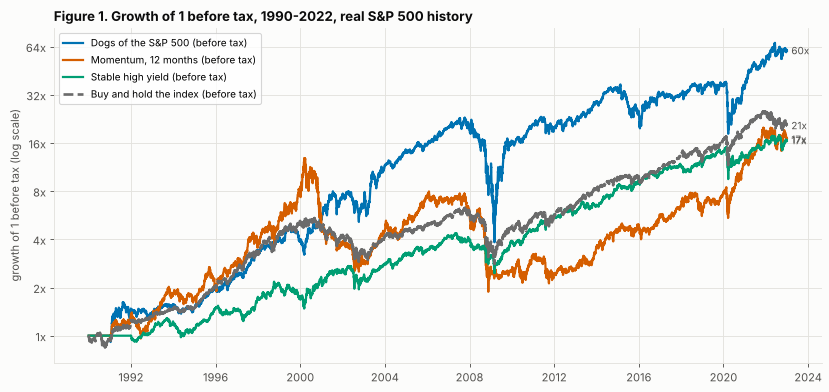

Table 1. Before tax, 1990-2022 (the index is the base case)


,Growth a year,Volatility,Worst fall,Worst 12 months,Growth minus the index,Years ahead of the index,Turnover a year,Names held
Buy and hold the index,9.6%,18.3%,-55.2%,-47.5%,-,-,-,-
Dogs of the S&P 500,13.2%,27.0%,-83.3%,-79.7%,3.6%,57.6%,73.9%,9.7
"Momentum, 12 months",8.9%,28.7%,-85.4%,-70.3%,-0.7%,54.5%,91.2%,9.7
Stable high yield,8.9%,15.4%,-43.7%,-29.8%,-0.7%,48.5%,48.4%,9.4


In [5]:
r0 = rep.reports["taxable"]
fig, ax = plt.subplots(figsize=(10.5, 5))
tp._ax(ax)
for k, s in enumerate(SCREENS):
    c = r0.results[s].curve / r0.results[s].curve.iloc[0]
    ax.plot(c.index, c.to_numpy(), color=tp.PALETTE[k], lw=2.0, label=f"{LABEL[s]} (before tax)")
    ax.annotate(f"{c.iloc[-1]:.0f}x", (c.index[-1], c.iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9, color=tp.INK2, va="center")
c = r0.benchmark / r0.benchmark.iloc[0]
ax.plot(c.index, c.to_numpy(), color=tp.INDEX_COL, ls="--", lw=2.4, label="Buy and hold the index (before tax)")
ax.annotate(f"{c.iloc[-1]:.0f}x", (c.index[-1], c.iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9, color=tp.INK2, va="center")
ax.set_yscale("log")
ax.set_yticks([1, 2, 4, 8, 16, 32, 64], minor=False)
ax.minorticks_off()
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}x")
ax.set_ylabel("growth of 1 before tax (log scale)")
ax.margins(x=0.05)
ax.legend(fontsize=9, loc="upper left")
ax.set_title("Figure 1. Growth of 1 before tax, 1990-2022, real S&P 500 history", loc="left", fontsize=12, fontweight="bold", color=tp.INK)
fig.tight_layout(); show(fig)

t1 = r0.table[["CAGR", "Vol", "MaxDD", "Worst12m", "Excess/yr", "BeatBenchYrs", "Turnover", "AvgN"]].copy()
t1.index = [LABEL[i] for i in t1.index]
t1 = t1.loc[[LABEL[INDEX], *[LABEL[s] for s in SCREENS]]]
t1.columns = ["Growth a year", "Volatility", "Worst fall", "Worst 12 months", "Growth minus the index", "Years ahead of the index", "Turnover a year", "Names held"]
print("Table 1. Before tax, 1990-2022 (the index is the base case)")
t1.style.format({c: "{:.1%}" for c in t1.columns[:7]} | {"Names held": "{:.1f}"}, na_rep="-")

In [6]:
d_ = dogs_yield
bound = bt0.table["CAGR"]
base_c = r0.table["CAGR"]
say(f'''
### What the evidence says

The history is as free of hindsight as the free data allows. The data card lists {card.n_names:,} names over the window, {card.n_delisted} of them delisted, and a survivorship estimate of {100 * card.survivorship_score:+.1f} points a year (the data card's measure of how much the data flatters the results; a figure near zero or below means survivors are not inflating them). The index held {min(members)} to {max(members)} names on the mid-year dates, so the screens always chose from about 500 companies, and a company that vanished while a rule held it took the library's delisting haircut of 30%.

On this history the dogs beat the base case before tax and the other two rules did not. The dogs grew {pc(base_c[DOGS])} a year against {pc(base_c[INDEX])} for buying and holding the index, a margin of {pts(base_c[DOGS] - base_c[INDEX])} points, and {pc(base_c['momentum_12m'])} for momentum and {pc(base_c['stable_high_yield'])} for stable high yield, both behind the index. The dogs paid for it in risk: a worst fall of {pc(-t1.loc[LABEL[DOGS], 'Worst fall'])} against {pc(-t1.loc[LABEL[INDEX], 'Worst fall'])} for the index, because the highest trailing yields in 2008-09 belonged to companies whose prices had collapsed (Section 6). With no delisting haircut the dogs would have grown {pc(bound[DOGS])} a year, so the haircut cost them {pts(bound[DOGS] - base_c[DOGS])} points and does not explain the lead. The rest of the notebook asks what tax does to a lead of this size.
''')
assert base_c[DOGS] > base_c[INDEX] > max(base_c[c] for c in COMP) and card.n_delisted > 100 and abs(card.survivorship_score) < 0.02


### What the evidence says

The history is as free of hindsight as the free data allows. The data card lists 1,248 names over the window, 631 of them delisted, and a survivorship estimate of -0.7 points a year (the data card's measure of how much the data flatters the results; a figure near zero or below means survivors are not inflating them). The index held 500 to 505 names on the mid-year dates, so the screens always chose from about 500 companies, and a company that vanished while a rule held it took the library's delisting haircut of 30%.

On this history the dogs beat the base case before tax and the other two rules did not. The dogs grew 13.24% a year against 9.59% for buying and holding the index, a margin of 3.64 points, and 8.94% for momentum and 8.88% for stable high yield, both behind the index. The dogs paid for it in risk: a worst fall of 83.33% against 55.25% for the index, because the highest trailing yields in 2008-09 belonged to companies whose prices had collapsed (Section 6). With no delisting haircut the dogs would have grown 14.31% a year, so the haircut cost them 1.07 points and does not explain the lead. The rest of the notebook asks what tax does to a lead of this size.


## 2. The three accounts for the dogs

Section 1 settled that the dogs beat the index before tax on real data. The question now is how much of that lead each account gives back, and how the index's own tax bill compares in the same account. The three accounts treat the same money differently. In a taxable account the dividends are taxed every year and the gains when a position is sold; a rule that turns over most of its portfolio every year sells and pays. In a TFSA nothing is taxed, but the 15% US withholding on every dividend is lost. In an RRSP the US dividends are exempt from withholding under the treaty, nothing is taxed while the money stays in, and the whole balance is taxed as income when it is withdrawn, here at 30% in one piece.

Every name in the panel is a US company, so every dividend is foreign: it is taxed as ordinary income in the taxable account, with the withholding credited against the Canadian tax, and the gains are measured in Canadian dollars using the real USDCAD rate. The tax is Alberta, other income \$90,000 a year, with the 2025 tables applied to every year of the run. The index is taxed on the same basis (all its dividends foreign), so it is a like-for-like base case.

### Growth before and after tax

Each panel in Figure 2 is one account. The thin pale lines are growth before tax and the thick lines are growth after tax. The coloured lines are the dogs and the two comparison rules, and the grey dashed line is the base case, the index bought and held in the same account. The scale is logarithmic and the number at the right edge of each line is the final multiple of the starting money.

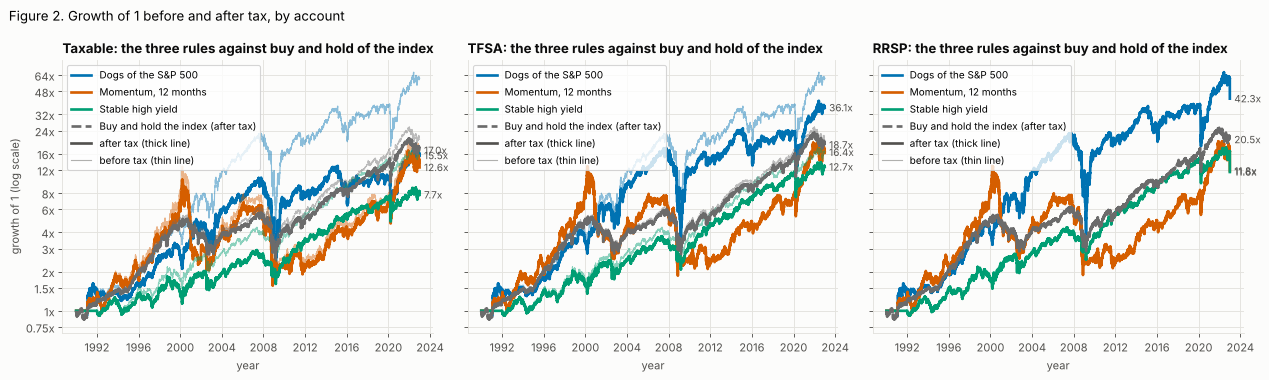

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, a in zip(axs, ACCOUNTS):
    r = rep.reports[a]
    tp.after_tax_curves({LABEL[s]: r.results[s] for s in SCREENS}, ax=ax, baseline=tp.index_result(r), baseline_label=BASE,
                        title=f"{NAME[a]}: the three rules against buy and hold of the index")
    ax.set_xlabel("year")
for ax in axs[1:]:
    ax.set_ylabel("")
fig.suptitle("Figure 2. Growth of 1 before and after tax, by account", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); show(fig)

### Tax paid, year by year

Figure 3 shows the dollars of tax paid by the dogs in each year on a \$100,000 start, split by what was taxed: dividends (all foreign here, so the bar is the withholding plus the Canadian tax left after the foreign tax credit), capital gains when a position is sold at a profit, and in the RRSP the withdrawal. In the TFSA the only tax is the withholding that cannot be recovered. Each panel has its own vertical scale, because the RRSP's single withdrawal bill is far larger than the yearly taxes of the other accounts. The grey dashed line with diamonds is the base case: the total tax paid each year by the index bought and held in the same account.

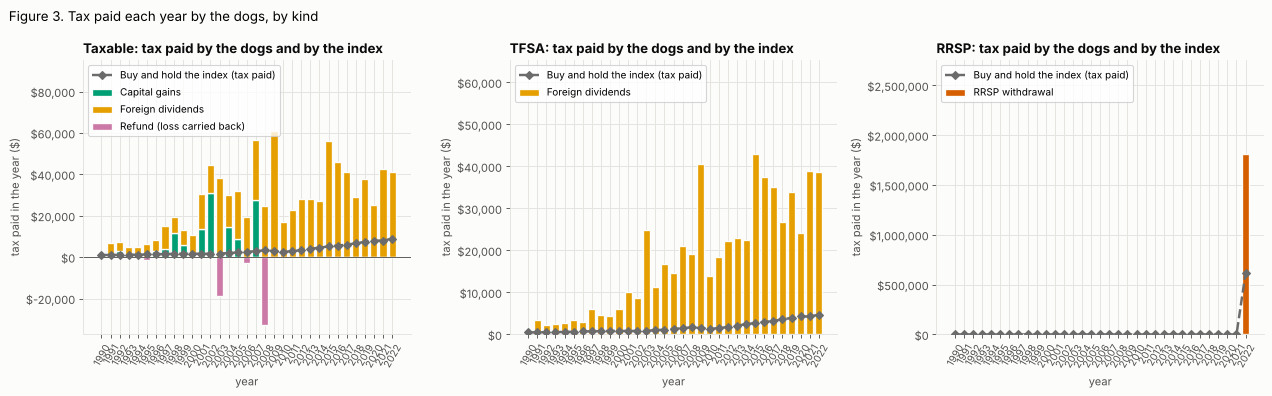

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, a in zip(axs, ACCOUNTS):
    r = rep.reports[a]
    tp.tax_paid_stack(r.results[DOGS], ax=ax, title=f"{NAME[a]}: tax paid by the dogs and by the index",
                      baseline=tp.index_result(r), baseline_label="Buy and hold the index (tax paid)")
    ax.set_xlabel("year")
    lo_, hi_ = ax.get_ylim()
    ax.set_ylim(lo_, hi_ * 1.45)                        # headroom for the legend
fig.suptitle("Figure 3. Tax paid each year by the dogs, by kind", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); show(fig)

### The tax drag, in points of growth a year

The tax drag is growth per year before tax minus growth per year after tax. In Figure 4 each group is a rule, the pale bar is its growth before tax, the dark bar its growth after tax in that account, the bold number the drag, and the grey dashed mark the base case: the index's growth after tax in the same account. A bar that ends below the grey mark means the rule finished behind buying and holding the index. Table 2 gives the same figures for every rule and account with the dollars on \$100,000, and Table 3 shows where the dogs' and the index's tax came from.

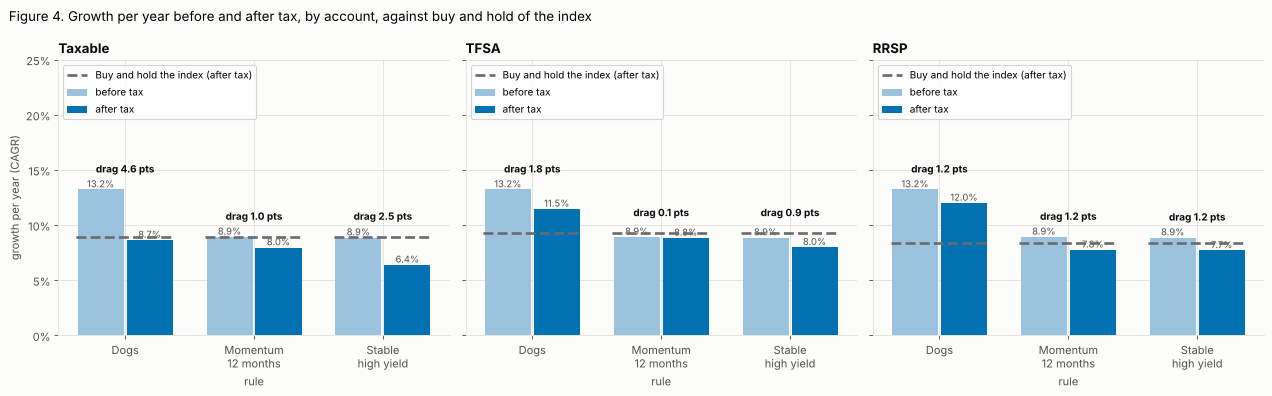

Table 2. Each holding in each account, on \$100,000 over 33 years (the index is the base case)


In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, a in zip(axs, ACCOUNTS):
    t = pd.DataFrame({"label": [LABEL[s] for s in SCREENS], "CAGR": [g(s, a, "pre") for s in SCREENS], "AfterTaxCAGR": [g(s, a, "post") for s in SCREENS]})
    tp.tax_drag_bars(t, ax=ax, title=f"{NAME[a]}", baseline=[g(INDEX, a, "post")] * len(SCREENS), baseline_label=BASE)
    ax.set_xticks(range(len(SCREENS)), ["Dogs", "Momentum\n12 months", "Stable\nhigh yield"])
    ax.set_xlabel("rule")
    ax.set_ylim(0, 0.25)                                 # headroom for the legend
for ax in axs[1:]:
    ax.set_ylabel("")
fig.suptitle("Figure 4. Growth per year before and after tax, by account, against buy and hold of the index", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); show(fig)

tbl = A.reset_index()
tbl["holding"] = tbl["name"].map(LABEL)
tbl["account"] = tbl["account"].map(NAME)
order = [(NAME[a], LABEL[n]) for a in ACCOUNTS for n in (INDEX, *SCREENS)]
tbl = tbl.set_index(["account", "holding"]).loc[order, ["pre", "post", "drag", "gap", "pre_usd", "post_usd", "tax_usd", "gap_usd"]]
tbl.columns = ["Growth a year before tax", "Growth a year after tax", "Tax drag (points a year)", "After-tax growth minus the index",
               f"Final value before tax", f"Final value after tax", "Final value lost to tax", "After-tax value minus the index"]
print(f"Table 2. Each holding in each account, on \\${CAP:,} over {YEARS:.0f} years (the index is the base case)")
tbl.style.format({c: "{:.2%}" for c in tbl.columns[:4]} | {c: "{:,.0f}" for c in tbl.columns[4:]}, na_rep="-")

In [10]:
src = A.reset_index()
src["holding"] = src["name"].map(LABEL)
src["account"] = src["account"].map(NAME)
src = src[src["name"].isin([DOGS, INDEX])].set_index(["account", "holding"]).loc[[(NAME[a], LABEL[n]) for a in ACCOUNTS for n in (INDEX, DOGS)]]
t3 = src[["divtax", "gaintax", "wdtax", "taxpaid", "wh_lost", "wh_cred", "wh_exempt"]].copy()
t3.columns = ["Tax on dividends (incl. withholding)", "Tax on gains", "Tax on the RRSP withdrawal", "Total tax paid",
              "Withholding lost (points a year)", "Withholding credited (points a year)", "Withholding exempt (points a year)"]
print(f"Table 3. Where the tax came from, dollars on \\${CAP:,} (sum of the yearly tax tables) and withholding as a yearly share of wealth")
t3.style.format({c: "{:,.0f}" for c in t3.columns[:4]} | {c: "{:.2%}" for c in t3.columns[4:]}, na_rep="-")

Table 3. Where the tax came from, dollars on \$100,000 (sum of the yearly tax tables) and withholding as a yearly share of wealth


In [11]:
n_ = (DOGS, INDEX)
say(f'''
### What the evidence says

The dogs kept {pc(g(DOGS, best_d, "post"))} a year in the {NAME[best_d]} and {pc(g(DOGS, worst_d, "post"))} in the {NAME[worst_d]}, from {pc(g(DOGS, tfsa, "pre"))} before tax. The taxable account cost {pts(g(DOGS, taxa, "drag"))} points a year, or {usd(g(DOGS, taxa, "tax_usd"))} of final value (the tax actually paid over the years was {usd(g(DOGS, taxa, "divtax"))} on dividends and {usd(g(DOGS, taxa, "gaintax"))} on gains, and the rest of the loss is the growth that money would have earned), because a rule that renews its portfolio every year realizes gains every year (turnover {t1.loc[LABEL[DOGS], "Turnover a year"]:.0%} a year) and its dividends, about {g(DOGS, tfsa, "wh_lost") / tax_config().rate_for("US"):.0%} of wealth a year, are taxed as ordinary income. The index in the same account paid {usd(g(INDEX, taxa, "taxpaid"))} in total, almost all on dividends, and lost {pts(g(INDEX, taxa, "drag"))} points a year, because it sells nothing and its dividends are thin. The TFSA cost the dogs {pts(g(DOGS, tfsa, "drag"))} points a year and the index {pts(g(INDEX, tfsa, "drag"))}: only the lost withholding, which is larger for the dogs because their yield is larger. The RRSP exempted the dividends from withholding and taxed the final balance at 30%, which cost the dogs {pts(g(DOGS, rrsp, "drag"))} points and the index {pts(g(INDEX, rrsp, "drag"))}; the two are nearly equal because a withdrawal tax of 30% takes the same share of any balance.

Against the base case, the account decided the verdict. Before tax the dogs led the index by {pts(g(DOGS, tfsa, "pre") - g(INDEX, tfsa, "pre"))} points a year. After tax that lead was {sp(g(DOGS, taxa, "gap"))} points in the taxable account, {sp(g(DOGS, tfsa, "gap"))} in the TFSA and {sp(g(DOGS, rrsp, "gap"))} in the RRSP, which on {usd(CAP)} is {sd(g(DOGS, taxa, "gap_usd"))}, {sd(g(DOGS, tfsa, "gap_usd"))} and {sd(g(DOGS, rrsp, "gap_usd"))}. In the taxable account the dogs paid {pts(g(DOGS, taxa, "drag") - g(INDEX, taxa, "drag"))} points a year more tax than the index, which is more than the whole {pts(g(DOGS, tfsa, "pre") - g(INDEX, tfsa, "pre"))} points of lead, so the rule had no after-tax advantage there, while the two sheltered accounts kept {pts(g(DOGS, tfsa, "gap"))} and {pts(g(DOGS, rrsp, "gap"))} points of it. Momentum and stable high yield trailed the index in every account, so no account rescued them.
''')
assert g(DOGS, taxa, "gap") < g(DOGS, tfsa, "gap") < g(DOGS, rrsp, "gap") and g(DOGS, tfsa, "gap") > 0 and g(DOGS, taxa, "drag") > g(DOGS, tfsa, "drag") > g(DOGS, rrsp, "drag")
assert g(DOGS, taxa, "gaintax") > 0 and g(INDEX, taxa, "gaintax") < 0.05 * g(INDEX, taxa, "taxpaid")
assert abs(g(DOGS, rrsp, "drag") - g(INDEX, rrsp, "drag")) < 0.002


### What the evidence says

The dogs kept 12.02% a year in the RRSP and 8.66% in the Taxable, from 13.24% before tax. The taxable account cost 4.57 points a year, or \$4,490,590 of final value (the tax actually paid over the years was \$752,127 on dividends and \$123,178 on gains, and the rest of the loss is the growth that money would have earned), because a rule that renews its portfolio every year realizes gains every year (turnover 74% a year) and its dividends, about 10% of wealth a year, are taxed as ordinary income. The index in the same account paid \$108,904 in total, almost all on dividends, and lost 0.65 points a year, because it sells nothing and its dividends are thin. The TFSA cost the dogs 1.76 points a year and the index 0.32: only the lost withholding, which is larger for the dogs because their yield is larger. The RRSP exempted the dividends from withholding and taxed the final balance at 30%, which cost the dogs 1.22 points and the index 1.18; the two are nearly equal because a withdrawal tax of 30% takes the same share of any balance.

Against the base case, the account decided the verdict. Before tax the dogs led the index by 3.64 points a year. After tax that lead was -0.28 points in the taxable account, +2.20 in the TFSA and +3.60 in the RRSP, which on \$100,000 is -\$139,560, +\$1,740,775 and +\$2,790,095. In the taxable account the dogs paid 3.93 points a year more tax than the index, which is more than the whole 3.64 points of lead, so the rule had no after-tax advantage there, while the two sheltered accounts kept 2.20 and 3.60 points of it. Momentum and stable high yield trailed the index in every account, so no account rescued them.


## 3. How much of the RRSP result is convention, and how much is the holding period

Section 2 gave the RRSP the best after-tax result for the dogs, but that result rests on two inputs that the notebook supplies and does not measure: the tax rate at withdrawal (30%) and how long the money stays in. The question here is how far the verdict moves when each is changed. In this model the RRSP is tax-deferred: nothing is taxed while the money stays in, and on the last day the whole balance is taxed as ordinary income at one rate, `rrsp_withdrawal_rate`. The deduction a contributor receives on the way in is not modelled, so the principal is taxed on the way out without ever having been credited, which is conservative for the RRSP.

### The withdrawal rate

Figure 5 shows after-tax growth per year against the withdrawal rate, for the dogs (colours) and for the base case (grey, one line style per account). The TFSA and taxable lines are flat because the withdrawal rate does not touch them; the RRSP lines fall as the rate rises. The RRSP figures are the same pre-tax balance taxed at each rate (a check in the code confirms that this reproduces the 30% run exactly). Table 4 gives the three rules and the base case.

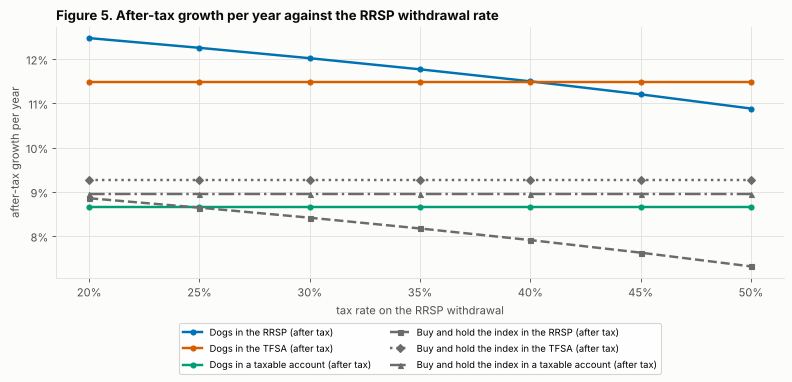

Table 4. After-tax growth per year against the RRSP withdrawal rate (taxable and TFSA do not depend on it)


In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
names = {f"{DOGS}_rrsp": "Dogs in the RRSP (after tax)", f"{DOGS}_tfsa": "Dogs in the TFSA (after tax)", f"{DOGS}_taxable": "Dogs in a taxable account (after tax)",
         f"{INDEX}_rrsp": "Buy and hold the index in the RRSP (after tax)", f"{INDEX}_tfsa": "Buy and hold the index in the TFSA (after tax)",
         f"{INDEX}_taxable": "Buy and hold the index in a taxable account (after tax)"}
tp.sensitivity_lines(by_rate, "rate", names, ax=ax, baseline=[f"{INDEX}_rrsp", f"{INDEX}_tfsa", f"{INDEX}_taxable"],
                     title="Figure 5. After-tax growth per year against the RRSP withdrawal rate",
                     xlabel="tax rate on the RRSP withdrawal", ylabel="after-tax growth per year")
ax.xaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")
ax.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout(); show(fig)

rr = []
for n in (INDEX, *SCREENS):
    for a in ("rrsp", "taxable", "tfsa"):
        rr.append(pd.Series(by_rate[f"{n}_{a}"].to_numpy(), index=[f"{r:.0%}" for r in RATES], name=(LABEL[n], NAME[a])))
t4 = pd.DataFrame(rr)
print("Table 4. After-tax growth per year against the RRSP withdrawal rate (taxable and TFSA do not depend on it)")
t4.style.format("{:.2%}")

### The length of the holding

The same three rules and the same 30% withdrawal rate were run again from the start of 2000, 2010 and 2015, each to the end of 2022, so that the holding periods are 23, 13 and 8 years against the 33 years of the main run. Real history gives each start its own sequence of markets, so the figure mixes the effect of the length with the effect of the decade. Figure 6 shows after-tax growth per year by start year for the dogs and the base case in each account, and Table 5 gives the margin over the index for each rule.

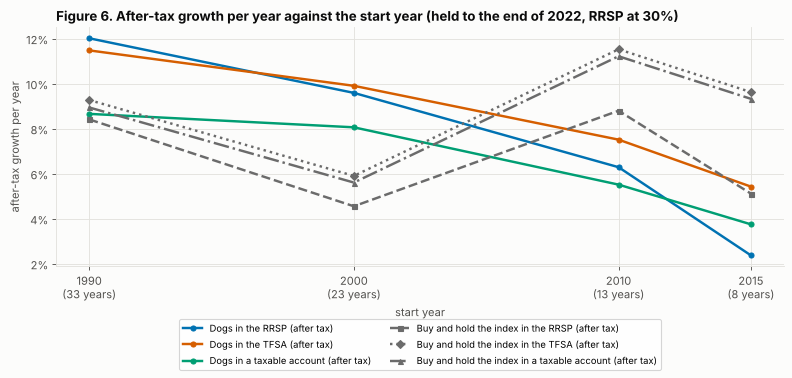

Table 5. Growth a year minus the index's, same account (points; the index is the base case, zero)


In [13]:
hp = pd.DataFrame({"start": STARTS})
for n in (DOGS, INDEX):
    for a in ACCOUNTS:
        hp[f"{n}_{a}"] = [HP[y].loc[(n, a), "post"] for y in STARTS]
fig, ax = plt.subplots(figsize=(10, 5))
names = {f"{DOGS}_{a}": f"Dogs in the {NAME[a]} (after tax)" if a != "taxable" else "Dogs in a taxable account (after tax)" for a in ("rrsp", "tfsa", "taxable")}
names |= {f"{INDEX}_{a}": f"Buy and hold the index in the {NAME[a]} (after tax)" if a != "taxable" else "Buy and hold the index in a taxable account (after tax)" for a in ("rrsp", "tfsa", "taxable")}
tp.sensitivity_lines(hp, "start", names, ax=ax, baseline=[f"{INDEX}_{a}" for a in ACCOUNTS],
                     title="Figure 6. After-tax growth per year against the start year (held to the end of 2022, RRSP at 30%)",
                     xlabel="start year", ylabel="after-tax growth per year")
ax.set_xticks(STARTS, [f"{y}\n({2022 - y + 1:.0f} years)" for y in STARTS])
ax.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout(); show(fig)

rows = {}
for n in SCREENS:
    for a in ACCOUNTS:
        rows[(LABEL[n], NAME[a])] = [HP[y].loc[(n, a), "gap"] for y in STARTS]
    rows[(LABEL[n], "Before tax")] = [HP[y].loc[(n, "tfsa"), "pre"] - HP[y].loc[(INDEX, "tfsa"), "pre"] for y in STARTS]
t5 = pd.DataFrame(rows, index=[f"from {y}" for y in STARTS]).T
t5 = t5.loc[[(LABEL[n], a) for n in SCREENS for a in ("Before tax", "Taxable", "TFSA", "RRSP")]]
print("Table 5. Growth a year minus the index's, same account (points; the index is the base case, zero)")
t5.style.format("{:+.2%}")

In [14]:
first, last = HP[1990], HP[2015]
cnt = {n: [(a, y) for a in ACCOUNTS for y in STARTS if HP[y].loc[(n, a), 'gap'] > 0] for n in COMP}
n_mom, n_shy = len(cnt['momentum_12m']), len(cnt['stable_high_yield'])
late = 'all in windows that began in ' + ', '.join(str(y) for y in sorted({y for n in COMP for _, y in cnt[n]})) if n_mom + n_shy else 'none of them'
def drag_row(y, n, a):
    return HP[y].loc[(n, a), "drag"]
say(f'''
### What the evidence says

The withdrawal rate decided the RRSP's rank, and the holding period decided whether the dogs deserved any rank at all. Across rates of {lo["rate"]:.0%} to {hi["rate"]:.0%} the dogs' after-tax growth in the RRSP fell from {pc(lo[f"{DOGS}_rrsp"])} to {pc(hi[f"{DOGS}_rrsp"])} a year, a swing of {pts(lo[f"{DOGS}_rrsp"] - hi[f"{DOGS}_rrsp"])} points, and the base case fell from {pc(lo[f"{INDEX}_rrsp"])} to {pc(hi[f"{INDEX}_rrsp"])}, a swing of {pts(lo[f"{INDEX}_rrsp"] - hi[f"{INDEX}_rrsp"])} points, so the two holdings moved together. Because the model gives the RRSP no deduction refund, it finishes level with the taxable account only when the withdrawal rate equals the share of final value that the taxable account lost to tax: {even_tax:.1%} for the dogs, and {1 - g(INDEX, taxa, "post_usd") / g(INDEX, rrsp, "pre_usd"):.1%} for the index. It finishes level with the TFSA at {even_tfsa:.1%} for the dogs, and at {1 - g(INDEX, tfsa, "post_usd") / g(INDEX, rrsp, "pre_usd"):.1%} for the index. The dogs' RRSP result beat their TFSA result at every withdrawal rate below {even_tfsa:.0%}; that break-even is the arithmetic of the missing refund and of the withholding a TFSA loses, not a property of the account.

The start year moved the verdict more than the rate did. The dogs' margin over the index in the RRSP was {sp(first.loc[(DOGS, rrsp), "gap"])} points a year from 1990, {sp(HP[2000].loc[(DOGS, rrsp), "gap"])} from 2000, {sp(HP[2010].loc[(DOGS, rrsp), "gap"])} from 2010 and {sp(last.loc[(DOGS, rrsp), "gap"])} from 2015, a range of {pts(first.loc[(DOGS, rrsp), "gap"] - last.loc[(DOGS, rrsp), "gap"])} points against {pts(lo[f"{DOGS}_rrsp"] - hi[f"{DOGS}_rrsp"])} for the whole range of withdrawal rates. Before tax the dogs' margin was {sp(first.loc[(DOGS, tfsa), "pre"] - first.loc[(INDEX, tfsa), "pre"])}, {sp(HP[2000].loc[(DOGS, tfsa), "pre"] - HP[2000].loc[(INDEX, tfsa), "pre"])}, {sp(HP[2010].loc[(DOGS, tfsa), "pre"] - HP[2010].loc[(INDEX, tfsa), "pre"])} and {sp(last.loc[(DOGS, tfsa), "pre"] - last.loc[(INDEX, tfsa), "pre"])} points over the same four windows, so most of that range came from the market and not from the tax. The RRSP's drag also depended on the length: {pts(drag_row(1990, DOGS, rrsp))} points a year for the dogs over 33 years and {pts(drag_row(2015, DOGS, rrsp))} over 8, because a one-time withdrawal tax of 30% (about {-100 * np.log(0.7):.0f}% of the final value in logarithmic terms) is spread over fewer years in a short run. The taxable drag stayed between {pts(min(HP[y].loc[(DOGS, taxa), "drag"] for y in STARTS))} and {pts(max(HP[y].loc[(DOGS, taxa), "drag"] for y in STARTS))} points for the dogs across the four windows. Momentum beat the index after tax in {n_mom} of the 12 combinations of account and start year and stable high yield in {n_shy}, and those were {late}.''')
assert (by_rate[f"{DOGS}_rrsp"].diff().dropna() < 0).all() and (by_rate[f"{INDEX}_rrsp"].diff().dropna() < 0).all()
assert first.loc[(DOGS, rrsp), "gap"] - last.loc[(DOGS, rrsp), "gap"] > lo[f"{DOGS}_rrsp"] - hi[f"{DOGS}_rrsp"]


### What the evidence says

The withdrawal rate decided the RRSP's rank, and the holding period decided whether the dogs deserved any rank at all. Across rates of 20% to 50% the dogs' after-tax growth in the RRSP fell from 12.47% to 10.88% a year, a swing of 1.59 points, and the base case fell from 8.86% to 7.32%, a swing of 1.54 points, so the two holdings moved together. Because the model gives the RRSP no deduction refund, it finishes level with the taxable account only when the withdrawal rate equals the share of final value that the taxable account lost to tax: 74.3% for the dogs, and 17.8% for the index. It finishes level with the TFSA at 40.3% for the dogs, and at 9.2% for the index. The dogs' RRSP result beat their TFSA result at every withdrawal rate below 40%; that break-even is the arithmetic of the missing refund and of the withholding a TFSA loses, not a property of the account.

The start year moved the verdict more than the rate did. The dogs' margin over the index in the RRSP was +3.60 points a year from 1990, +5.04 from 2000, -2.51 from 2010 and -2.74 from 2015, a range of 6.34 points against 1.59 for the whole range of withdrawal rates. Before tax the dogs' margin was +3.64, +5.11, -2.58 and -2.87 points over the same four windows, so most of that range came from the market and not from the tax. The RRSP's drag also depended on the length: 1.22 points a year for the dogs over 33 years and 4.67 over 8, because a one-time withdrawal tax of 30% (about 36% of the final value in logarithmic terms) is spread over fewer years in a short run. The taxable drag stayed between 3.24 and 4.57 points for the dogs across the four windows. Momentum beat the index after tax in 6 of the 12 combinations of account and start year and stable high yield in 4, and those were all in windows that began in 2000, 2010, 2015.

## 4. What the bracket and the province change

Sections 2 and 3 held the tax law fixed at an Alberta resident with \$90,000 of other income, and Section 3 treated the RRSP withdrawal rate as a free input. The question now is how much the result moves when the bracket or the province changes, and part of what sets a sensible withdrawal rate is the bracket, which is the subject here. Kinds of income are not taxed alike, and the dogs and the index earn their money in different mixes: both receive only US dividends, which are taxed as ordinary income, but the dogs also sell every year and realize gains, which are taxed at half the ordinary rate.

### The tax on the next dollar

Figure 7 shows the tax on the next \$1 of each kind of income, stacked on top of other income, for Alberta (solid) and British Columbia (dashed). The grey wide dashed line is the base case: the index bought and held earns only US dividends, which are taxed as ordinary income, so its marginal rate is the ordinary-income line. Incomes under about \$30,000 are left off the vertical scale because there is little tax to measure there, and the black line is zero.

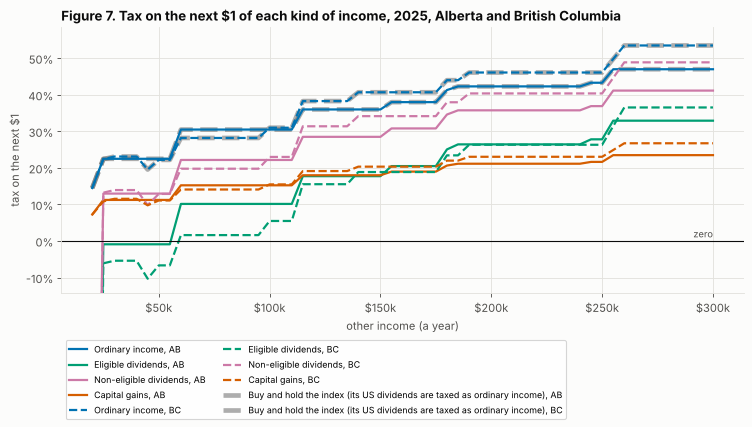

Table 6. Tax on the next dollar of each kind of income, by other income


In [15]:
fig, ax = plt.subplots(figsize=(9.5, 5.6))
tp.marginal_rate_curves(("AB", "BC"), 2025, range(20_000, 300_001, 5_000), ax=ax, baseline="ordinary",
                        baseline_label="Buy and hold the index (its US dividends are taxed as ordinary income)",
                        title="Figure 7. Tax on the next \\$1 of each kind of income, 2025, Alberta and British Columbia")
fig.tight_layout(); show(fig)

mr = {prov: pd.DataFrame([marginal_rates(prov, 2025, float(i)) for i in INCOMES], index=INCOMES) for prov in ("AB", "BC")}
kinds = [("ordinary", "Buy and hold the index: US dividends, taxed as ordinary income"), ("capital_gain", "Capital gains (the dogs' sales)"),
         ("eligible_dividend", "Eligible Canadian dividends (not held here)"), ("non_eligible_dividend", "Non-eligible dividends (not held here)")]
mt = pd.DataFrame({(prov, f"${i // 1000}k"): [mr[prov].loc[i, k] for k, _ in kinds] for prov in ("AB", "BC") for i in INCOMES}, index=[n for _, n in kinds])
print("Table 6. Tax on the next dollar of each kind of income, by other income")
mt.style.format("{:.1%}")

### The same rules at three incomes in two provinces

Only the taxable account is shown, because the TFSA pays no Canadian tax and the RRSP result depends on the withdrawal rate and not on today's bracket. Figure 8 and Table 7 give after-tax growth for the dogs and for the base case in Alberta and British Columbia at other income of \$30,000, \$90,000 and \$200,000, with the two comparison rules for Alberta (the British Columbia runs cover the dogs and the index only, to keep the run time down).

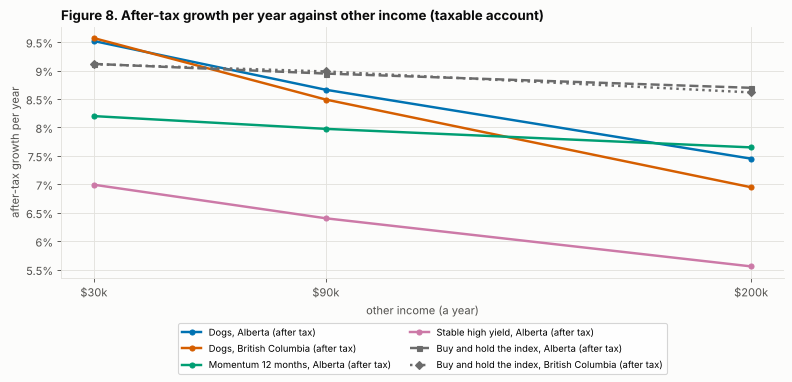

Table 7. After-tax growth per year, taxable account (the index is the base case; British Columbia comparison rules not run)


In [16]:
bb = by_bracket.pivot_table(index="other_income", columns=["name", "province"], values="post")
wide = pd.DataFrame({"other_income": bb.index})
for (n, prov) in bb.columns:
    wide[f"{n}_{prov}"] = bb[(n, prov)].to_numpy()
names = {f"{DOGS}_AB": "Dogs, Alberta (after tax)", f"{DOGS}_BC": "Dogs, British Columbia (after tax)",
         "momentum_12m_AB": "Momentum 12 months, Alberta (after tax)", "stable_high_yield_AB": "Stable high yield, Alberta (after tax)",
         f"{INDEX}_AB": "Buy and hold the index, Alberta (after tax)", f"{INDEX}_BC": "Buy and hold the index, British Columbia (after tax)"}
fig, ax = plt.subplots(figsize=(10, 5))
tp.sensitivity_lines(wide, "other_income", names, ax=ax, baseline=[f"{INDEX}_AB", f"{INDEX}_BC"],
                     title="Figure 8. After-tax growth per year against other income (taxable account)",
                     xlabel="other income (a year)", ylabel="after-tax growth per year")
ax.set_xticks(wide["other_income"], ["\\$30k", "\\$90k", "\\$200k"])
ax.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout(); show(fig)

t7 = by_bracket.pivot_table(index=["province", "other_income"], columns="name", values="post")[[INDEX, *SCREENS]]
t7["dogs_gap"] = t7[DOGS] - t7[INDEX]
t7.columns = [LABEL[c] if c in LABEL else "Dogs minus buy and hold" for c in t7.columns]
t7.index = pd.MultiIndex.from_tuples([({"AB": "Alberta", "BC": "British Columbia"}[p], f"${i:,}") for p, i in t7.index], names=["province", "other income"])
print("Table 7. After-tax growth per year, taxable account (the index is the base case; British Columbia comparison rules not run)")
t7.style.format("{:.2%}", na_rep="-")

In [17]:
mrab, mrbc = mr["AB"], mr["BC"]
p30, p90, p200 = INCOMES
dg_ab = {i: b[("AB", i, DOGS)] - b[("AB", i, INDEX)] for i in INCOMES}
say(f'''
### What the evidence says

The bracket decided whether the dogs beat the base case in the taxable account. In Alberta the next dollar of ordinary income, the base case's US dividends, was taxed at {mrab.loc[p30, "ordinary"]:.1%} at {usd(p30)} of other income, {mrab.loc[p90, "ordinary"]:.1%} at {usd(p90)} and {mrab.loc[p200, "ordinary"]:.1%} at {usd(p200)}, while a capital gain was taxed at {mrab.loc[p30, "capital_gain"]:.1%}, {mrab.loc[p90, "capital_gain"]:.1%} and {mrab.loc[p200, "capital_gain"]:.1%}. Both holdings lost ground as income rose: the dogs fell from {pc(bk_lo)} to {pc(bk_hi)} a year between {usd(p30)} and {usd(p200)} (a loss of {pts(bk_lo - bk_hi)} points) and the index from {pc(bi_lo)} to {pc(bi_hi)} ({pts(bi_lo - bi_hi)} points). The dogs fell about {(bk_lo - bk_hi) / (bi_lo - bi_hi):.1f} times as far, which fits a portfolio that pays larger dividends, taxed as ordinary income, and sells every year. Their margin over the index went from {sp(dg_ab[p30])} points at {usd(p30)} to {sp(dg_ab[p90])} at {usd(p90)} and {sp(dg_ab[p200])} at {usd(p200)}. The two comparison rules lost {pts(b[("AB", p30, "momentum_12m")] - b[("AB", p200, "momentum_12m")])} and {pts(b[("AB", p30, "stable_high_yield")] - b[("AB", p200, "stable_high_yield")])} points over the same range.

The province mattered much less than the bracket. Moving from Alberta to British Columbia changed the dogs' after-tax growth by {pts(abs(b[("BC", p30, DOGS)] - bk_lo))} points at {usd(p30)}, {pts(abs(b[("BC", p90, DOGS)] - b[("AB", p90, DOGS)]))} at {usd(p90)} and {pts(abs(b[("BC", p200, DOGS)] - bk_hi))} at {usd(p200)}, and the index's by {pts(abs(b[("BC", p30, INDEX)] - bi_lo))}, {pts(abs(b[("BC", p90, INDEX)] - b[("AB", p90, INDEX)]))} and {pts(abs(b[("BC", p200, INDEX)] - bi_hi))} points, each below the {pts(bk_lo - bk_hi)} points that the bracket moved the dogs in Alberta. Some British Columbia constants are unverified (see the end of the notebook), so the province comparison is indicative only. The TFSA is untouched by the bracket, and the RRSP depends on it only through the withdrawal rate that Section 3 varied.
''')
assert (by_bracket.groupby(["province", "name"])["post"].diff().dropna() < 0).all()
assert dg_ab[p30] > 0 > dg_ab[p200] and (bk_lo - bk_hi) > (bi_lo - bi_hi)
assert all(abs(b[("BC", k, DOGS)] - b[("AB", k, DOGS)]) < bk_lo - bk_hi for k in INCOMES)


### What the evidence says

The bracket decided whether the dogs beat the base case in the taxable account. In Alberta the next dollar of ordinary income, the base case's US dividends, was taxed at 22.5% at \$30,000 of other income, 30.5% at \$90,000 and 42.3% at \$200,000, while a capital gain was taxed at 11.2%, 15.2% and 21.2%. Both holdings lost ground as income rose: the dogs fell from 9.52% to 7.45% a year between \$30,000 and \$200,000 (a loss of 2.07 points) and the index from 9.12% to 8.70% (0.42 points). The dogs fell about 4.9 times as far, which fits a portfolio that pays larger dividends, taxed as ordinary income, and sells every year. Their margin over the index went from +0.40 points at \$30,000 to -0.28 at \$90,000 and -1.25 at \$200,000. The two comparison rules lost 0.55 and 1.44 points over the same range.

The province mattered much less than the bracket. Moving from Alberta to British Columbia changed the dogs' after-tax growth by 0.05 points at \$30,000, 0.17 at \$90,000 and 0.50 at \$200,000, and the index's by 0.01, 0.04 and 0.08 points, each below the 2.07 points that the bracket moved the dogs in Alberta. Some British Columbia constants are unverified (see the end of the notebook), so the province comparison is indicative only. The TFSA is untouched by the bracket, and the RRSP depends on it only through the withdrawal rate that Section 3 varied.


## 5. The same question for the other screens

Sections 2 to 4 followed the dogs, which led the index before tax. The question here is whether the account and the tax change the picture for the two rules that did not: which account suits each rule, and how far each finishes from the base case. The comparison matters because a rule can be best in one account and still behind the index, and because a rule that trades often and a rule that holds a thin, steady portfolio meet the tax differently. The data has no market capitalization, so the value and buyback screens of the library cannot run on it; the three rules here are the ones that need only prices and dividends.

Figure 9 shows each rule's after-tax growth minus the index's in the same account, so the grey dashed line at zero is the base case (buy and hold of the index, whatever the account). A bar above the line is a rule that beat the index after tax in that account. Table 8 gives the growth rates, the drag and the rank of the accounts for each rule.

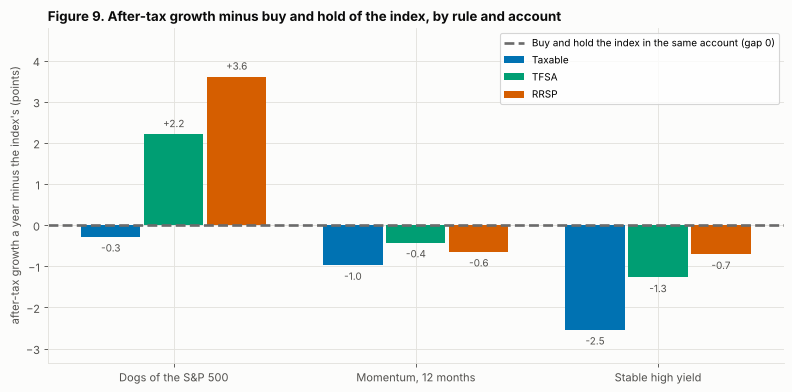

Table 8. Each holding in each account, 1990-2022; rank 1 is the best account for that holding (the index is the base case)


In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
tp._ax(ax)
w = 0.26
ACOL = {"taxable": tp.PALETTE[0], "tfsa": tp.PALETTE[2], "rrsp": tp.PALETTE[1]}
for k, a in enumerate(ACCOUNTS):
    vals = [100 * g(s, a, "gap") for s in SCREENS]
    xs = np.arange(len(SCREENS)) + (k - 1) * w
    ax.bar(xs, vals, w * 0.94, color=ACOL[a], label=f"{NAME[a]}")
    for x_, v in zip(xs, vals):
        ax.text(x_, v + (0.12 if v >= 0 else -0.12), f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9, color=tp.INK2)
ax.axhline(0, color=tp.INDEX_COL, ls="--", lw=2.4, label="Buy and hold the index in the same account (gap 0)")
ax.set_xticks(range(len(SCREENS)), [LABEL[s] for s in SCREENS])
ax.set_ylabel("after-tax growth a year minus the index's (points)")
ax.set_ylim(min(0, 100 * min(g(s, a, "gap") for s in SCREENS for a in ACCOUNTS)) - 0.8, 100 * max(g(s, a, "gap") for s in SCREENS for a in ACCOUNTS) + 1.2)
ax.legend(fontsize=9, loc="upper right")
ax.set_title("Figure 9. After-tax growth minus buy and hold of the index, by rule and account", loc="left", fontsize=12, fontweight="bold", color=tp.INK)
fig.tight_layout(); show(fig)

rows = []
for n in (INDEX, *SCREENS):
    for a in ACCOUNTS:
        rows.append({"Holding": LABEL[n], "Account": NAME[a], "Growth before tax": g(n, a, "pre"), "Growth after tax": g(n, a, "post"),
                     "Tax drag (points)": g(n, a, "drag"), "Minus the index": g(n, a, "gap"), "Rank of the account": g(n, a, "rank")})
t8 = pd.DataFrame(rows).set_index(["Holding", "Account"])
print("Table 8. Each holding in each account, 1990-2022; rank 1 is the best account for that holding (the index is the base case)")
t8.style.format({c: "{:.2%}" for c in t8.columns[:4]} | {"Minus the index": "{:+.2%}", "Rank of the account": "{:.0f}"}, na_rep="-")

In [19]:
rk = {n: ", ".join(NAME[a] for a in sorted(ACCOUNTS, key=lambda a: g(n, a, "rank"))) for n in (INDEX, *SCREENS)}
say(f'''
### What the evidence says

The best account differed by rule. Ranked from best to worst after tax, the accounts were {rk[DOGS]} for the dogs, {rk["momentum_12m"]} for momentum, {rk["stable_high_yield"]} for stable high yield and {rk[INDEX]} for the index. The dogs gained most from the RRSP and the others from the TFSA because the dogs pay the most dividends: a TFSA loses the 15% US withholding on all of them, while an RRSP is exempt under the treaty, and the cost of the RRSP is the 30% withdrawal tax taken from a larger balance. Momentum and stable high yield pay little by comparison and held up best where the tax was lowest, and their drags in the taxable account were {pts(g("momentum_12m", taxa, "drag"))} and {pts(g("stable_high_yield", taxa, "drag"))} points a year against {pts(g(DOGS, taxa, "drag"))} for the dogs.

The gap to the base case was the second finding. After tax the dogs were {sp(g(DOGS, taxa, "gap"))}, {sp(g(DOGS, tfsa, "gap"))} and {sp(g(DOGS, rrsp, "gap"))} points a year from the index in the taxable account, the TFSA and the RRSP. Momentum was {sp(g("momentum_12m", taxa, "gap"))}, {sp(g("momentum_12m", tfsa, "gap"))} and {sp(g("momentum_12m", rrsp, "gap"))} and stable high yield {sp(g("stable_high_yield", taxa, "gap"))}, {sp(g("stable_high_yield", tfsa, "gap"))} and {sp(g("stable_high_yield", rrsp, "gap"))}. No account made either of them beat buying and holding the index, and the nearest either came was {pts(-max(g(n, a, "gap") for n in COMP for a in ACCOUNTS))} points behind it. The dogs were the only rule whose result depended on choosing the account correctly: a mistake cost them {pts(g(DOGS, best_d, "post") - g(DOGS, worst_d, "post"))} points a year, while the index lost {pts(g(INDEX, best_i, "post") - g(INDEX, worst_i, "post"))} points to the same mistake.
''')
assert all(g(n, a, "gap") < 0 for n in COMP for a in ACCOUNTS)


### What the evidence says

The best account differed by rule. Ranked from best to worst after tax, the accounts were RRSP, TFSA, Taxable for the dogs, TFSA, Taxable, RRSP for momentum, TFSA, RRSP, Taxable for stable high yield and TFSA, Taxable, RRSP for the index. The dogs gained most from the RRSP and the others from the TFSA because the dogs pay the most dividends: a TFSA loses the 15% US withholding on all of them, while an RRSP is exempt under the treaty, and the cost of the RRSP is the 30% withdrawal tax taken from a larger balance. Momentum and stable high yield pay little by comparison and held up best where the tax was lowest, and their drags in the taxable account were 0.97 and 2.48 points a year against 4.57 for the dogs.

The gap to the base case was the second finding. After tax the dogs were -0.28, +2.20 and +3.60 points a year from the index in the taxable account, the TFSA and the RRSP. Momentum was -0.97, -0.43 and -0.65 and stable high yield -2.54, -1.27 and -0.71. No account made either of them beat buying and holding the index, and the nearest either came was 0.43 points behind it. The dogs were the only rule whose result depended on choosing the account correctly: a mistake cost them 3.36 points a year, while the index lost 0.86 points to the same mistake.


## 6. Reading guide: what is real and what is approximate

Section 5 completed the comparison, and the question left is how much of it to trust. The inputs fall into three groups: what comes straight from the real record, what is an approximation made by the model, and what is a property of the dogs rule that a reader might not expect. Table 9 and Table 10 put numbers on the two approximations that matter most for the dogs, the delisting haircut and the distressed companies that the trailing yield selects.

**Real.** The prices and cash dividends of every company, the dates each was in the S&P 500, the S&P 500 total return used as the base case, the USDCAD exchange rate used to measure gains in Canadian dollars, and the 15% US withholding on dividends.

**Approximate.** The 2025 Canadian tax tables are applied to every year from 1990 to 2022, because no earlier tables exist in the library (a warning is printed in the run); other income is a flat \$90,000 in every year; the RRSP withdrawal rate of 30% is an assumption and the deduction refund is left out. A company whose prices end (merged, bankrupt, delisted) takes a haircut of 30% of its last value, which is harsh for a takeover at a premium and kind for a bankruptcy. The screens do not see market capitalization or fundamentals, because the panel has none: `dogs` is the ten highest trailing yields of the whole index and not of its 30 largest names, and `stable_high_yield` takes the 50 least volatile payers of the whole index.

**Licence.** The panel is an unlicensed mixed-source dataset, so the notebook reads it from a git-ignored folder on your machine and the repository stores none of it.

In [20]:
t9 = pd.DataFrame({"Haircut of 30% (as run)": base_c.reindex([INDEX, *SCREENS]), "No haircut": bound.reindex([INDEX, *SCREENS])})
t9.index = [LABEL[i] for i in t9.index]
t9["Difference (points)"] = t9["No haircut"] - t9["Haircut of 30% (as run)"]
print("Table 9. Growth a year before tax, with and without the delisting haircut (the index has no delistings of its own)")
display(t9.style.format("{:.2%}"))

t10 = dogs_yield.copy()
t10.index = [d.strftime("%Y-%m-%d") for d in t10.index]
sel = t10.sort_values("mean_yield", ascending=False).head(6).sort_index()
sel.columns = ["Average yield of the ten", "Highest yield", "Name with the highest yield", "Names yielding over 20%", "Names whose ticker later ends"]
print("Table 10. The dogs at the six formation dates with the highest average yield (a high trailing yield after a price collapse is kept)")
sel.style.format({"Average yield of the ten": "{:.1%}", "Highest yield": "{:.1%}"})

Table 9. Growth a year before tax, with and without the delisting haircut (the index has no delistings of its own)


,Haircut of 30% (as run),No haircut,Difference (points)
Buy and hold the index,9.59%,9.59%,0.00%
Dogs of the S&P 500,13.24%,14.31%,1.07%
"Momentum, 12 months",8.94%,10.95%,2.01%
Stable high yield,8.88%,9.38%,0.50%


Table 10. The dogs at the six formation dates with the highest average yield (a high trailing yield after a price collapse is kept)


,Average yield of the ten,Highest yield,Name with the highest yield,Names yielding over 20%,Names whose ticker later ends
1991-01-02,16.3%,21.0%,FG-199804,3,7
1995-01-03,12.3%,24.7%,PCAR,1,4
2003-01-02,18.6%,60.7%,LU-200611,2,7
2009-01-02,33.6%,84.0%,ACAS-201701,6,3
2015-01-02,13.3%,32.2%,NE-202102,2,1
2016-01-04,12.4%,32.3%,TGNA,1,0


In [21]:
rank_by = {y: sorted(ACCOUNTS, key=lambda a: -HP[y].loc[(DOGS, a), 'post']) for y in STARTS}
order_text = '; '.join(f"from {y} {', '.join(NAME[a] for a in rank_by[y])}" for y in STARTS)
n_tax_last = sum(rank_by[y][-1] == 'taxable' for y in STARTS)
n_tfsa_first = sum(rank_by[y][0] == 'tfsa' for y in STARTS)
share_gone = dogs_yield["later_delisted"].sum() / (10 * len(dogs_yield))
top = dogs_yield.sort_values("mean_yield", ascending=False).iloc[0]
say(f'''
### What the evidence says

The dogs' lead over the index is real data but a fragile number. The delisting haircut moved the dogs' growth by {pts(bound[DOGS] - base_c[DOGS])} points a year and the other two rules by {pts(bound["momentum_12m"] - base_c["momentum_12m"])} and {pts(bound["stable_high_yield"] - base_c["stable_high_yield"])}, so it does not decide any ranking. The distressed-name effect matters more: at the formation date of {top.name:%B %Y} the ten dogs yielded {top["mean_yield"]:.0%} on average, {int(top["over_20"])} of them above 20%, because their prices had fallen far, and over the whole run {share_gone:.0%} of the dog positions were in tickers that the panel marks with an end date. A trailing yield that high usually follows a price collapse, so it is as likely to be a warning as an income, and the dogs' worst fall was {pc(-t1.loc[LABEL[DOGS], "Worst fall"])} against {pc(-t1.loc[LABEL[INDEX], "Worst fall"])} for the index. The order of the accounts for the dogs depended on the window: {order_text}. What the windows share is the structure of the tax, not one ranking: the taxable account came last in {n_tax_last} of the 4 windows and the TFSA first in {n_tfsa_first}. The size of each gap depends on the 2025 tables, the 30% withdrawal assumption and the 33-year path, and the dogs' lead over the index depended on the decade chosen (Section 3). The dividends here are all US; a Canadian-dollar investor who held the same names through a Canadian-listed fund would lose the withholding in every account (the foreign-holdings notebook shows the matrix).
''')
assert (bound[DOGS] - base_c[DOGS]) > 0


### What the evidence says

The dogs' lead over the index is real data but a fragile number. The delisting haircut moved the dogs' growth by 1.07 points a year and the other two rules by 2.01 and 0.50, so it does not decide any ranking. The distressed-name effect matters more: at the formation date of January 2009 the ten dogs yielded 34% on average, 6 of them above 20%, because their prices had fallen far, and over the whole run 34% of the dog positions were in tickers that the panel marks with an end date. A trailing yield that high usually follows a price collapse, so it is as likely to be a warning as an income, and the dogs' worst fall was 83.33% against 55.25% for the index. The order of the accounts for the dogs depended on the window: from 1990 RRSP, TFSA, Taxable; from 2000 TFSA, RRSP, Taxable; from 2010 TFSA, RRSP, Taxable; from 2015 TFSA, Taxable, RRSP. What the windows share is the structure of the tax, not one ranking: the taxable account came last in 3 of the 4 windows and the TFSA first in 3. The size of each gap depends on the 2025 tables, the 30% withdrawal assumption and the 33-year path, and the dogs' lead over the index depended on the decade chosen (Section 3). The dividends here are all US; a Canadian-dollar investor who held the same names through a Canadian-listed fund would lose the withholding in every account (the foreign-holdings notebook shows the matrix).


### What this ignores

* **Contribution room.** A TFSA or RRSP holds only what the room allows. Each account here was given all the money in turn.
* **The RRSP deduction refund.** The tax saved when you contribute is not modelled. It is the main reason an RRSP wins for someone in a higher bracket now than at retirement, and it is why the RRSP looks weaker here than it can be, especially over short periods. Modelling it needs your contribution amounts and your bracket in each year.
* **AMT, benefit clawbacks, the age credit, pension splitting** and the interaction of withdrawals with OAS are not in the model.
* **Tax tables.** Only the 2025 tables exist, and every year of the run uses them (the operation says so). Alberta numbers are the owner's reference; the **British Columbia constants are partly marked UNVERIFIED** in `tax_ca/tables.py` (the non-eligible dividend credit rate, the absence of a surtax or health premium, a possible change for 2026), so differences between British Columbia and Alberta are indicative only.
* **The data.** Real, point-in-time and bias-free in membership, but mixed-source (CRSP, Yahoo, Tiingo, Quandl WIKI), unlicensed and local only. There is no market capitalization, so value and buyback screens cannot be tested; the delisting haircut is a flat 30%; and the screens hold cash in 1990.
* **Costs and execution.** Default trading costs, rebalancing once a year on the first trading day, no taxes on the cash held, no wash-sale or superficial-loss rule (the loss-harvesting notebook covers it).
* **Not tax advice.** Check figures against the CRA and provincial sources for the year.